# 第 2 课 C：图像、通道与一批数据

**核心问题：一张小图为什么只有两条轴，送入模型的一批图却常有四条轴？**

上一节的复核答案已经正确：保持 8～12 的参考范围，10 和 13 kHz 分别变成 0.5 和 1.25。这里不继续加归一化练习。

今天只学一条形状变化链：**一张二维图 → 显式加上通道轴 → 把多张图组成一个 batch**。

我准备了一个 5×7 的极小网格和配套示意图；你负责解释每条轴，并把一批两张图改成三张。先不用学习卷积计算、训练或真实声谱图生成。

## 0．沿用现有环境

课件使用你已有服务的 `Python 3 (ipykernel)` 名称。先确认下面输出是 `D:\Anaconda3\envs\HEUhuqiao\python.exe`。名称相同不保证路径相同；若路径不同，先选择已有的 HEUhuqiao 解释器，不必新建环境。

In [1]:
import sys
print(sys.executable)

D:\Anaconda3\envs\HEUhuqiao\python.exe


## 1．同一类曲线，换成网格表示

这次为了让高、宽容易区分，使用 **5 个频率格、7 个时间格**。曲线在 0～0.6 秒的七个时间点取频率：

```text
时间（s）： 0   0.1  0.2  0.3  0.4  0.5  0.6
频率（kHz）：8    9   10   12   10    9    8
```

在网格里：第 0～4 行分别代表 8、9、10、11、12 kHz；第 0～6 列对应上述七个时间点。经过的位置填 1，其他位置填 0。

下面每个内部列表是一行。变量名后缀 `hw` 提醒我们轴顺序是 Height（高度）、Width（宽度）；后缀只是我们起的名字。

**关键区别：**过去列表中的 12 是频率值；这里的 1 是“曲线经过此格”的标记，频率由行的位置表示。它不是概率或真实声能量。这是一幅手工制作的二值轨迹图，不是由录音做短时傅里叶变换得到的声谱图，也不是论文完整的数据处理流程。

In [2]:
import torch

image_hw = torch.tensor([
    [1, 0, 0, 0, 0, 0, 1],  # 8 kHz
    [0, 1, 0, 0, 0, 1, 0],  # 9 kHz
    [0, 0, 1, 0, 1, 0, 0],  # 10 kHz
    [0, 0, 0, 0, 0, 0, 0],  # 11 kHz
    [0, 0, 0, 1, 0, 0, 0],  # 12 kHz
], dtype=torch.float32, device="cpu")
print("shape：", image_hw.shape)
print("总元素数：", image_hw.numel())

shape： torch.Size([5, 7])
总元素数： 35


### 先看图，再对应数值

下面是我按上方原始数据预先生成的静态示意图，已嵌入 Notebook，无需联网或运行绘图库。

- 0 用白格、1 用黑格显示；颜色只是显示规则。
- 数组第 0 行画在底部，所以频率向上增加。
- 横轴是时间，纵轴是频率；不是每一行代表一张图。

本图用于对应初始数组。若之后修改数组，静态图不会自动刷新；本节练习改的是 batch，不要求你修改或重画这张图。

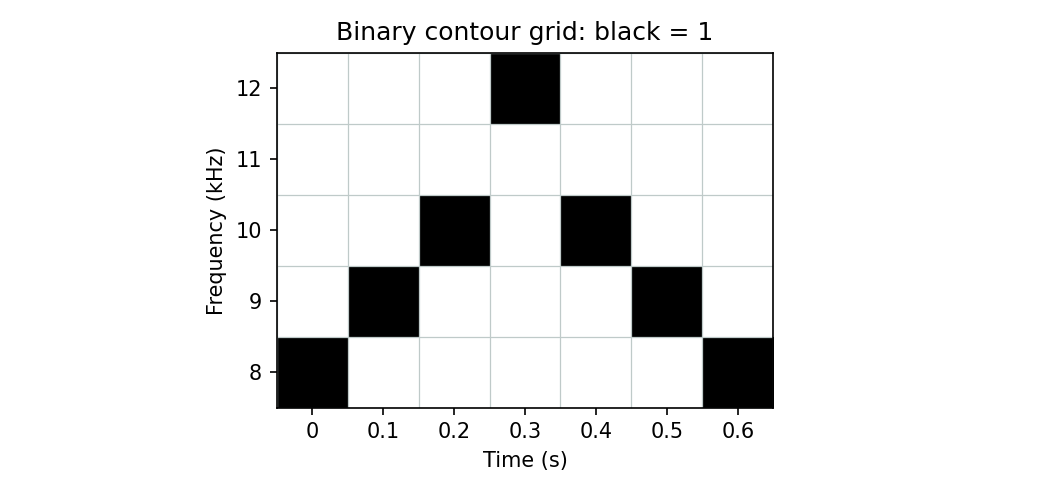

**观察任务：**找到 0.3 秒、12 kHz 的黑格，对应数组的哪一行、哪一列？

## 2．加上通道轴：一层图，也可以明确写出一层

目前 `image_hw.shape` 是 `(5, 7)`，每个格子只有一个数，即单通道图。通道可以理解为同一张图中每个位置记录的不同分量；例如 RGB 彩色图通常有红、绿、蓝三个通道，而本例只有一个标记值。

本课采用 **`(C, H, W)`：通道数、高度、宽度** 的顺序。`C` 来自 Channel，不是 Curve；通道不是曲线条数，也不是麦克风数量的固定含义。

`image_hw.unsqueeze(0)` 在轴位置 0 插入一条长度为 1 的轴。这个 0 指插入位置，不是“零个通道”，也不是往像素里添加数值 0。

In [8]:
first_chw = image_hw.unsqueeze(0)
print("原形状：", image_hw.shape)
print("加入通道轴：", first_chw.shape)
print("ndim：", first_chw.ndim)
print("总元素数：", first_chw.numel())
print(first_chw)

原形状： torch.Size([5, 7])
加入通道轴： torch.Size([1, 5, 7])
ndim： 3
总元素数： 35
tensor([[[1., 0., 0., 0., 0., 0., 1.],
         [0., 1., 0., 0., 0., 1., 0.],
         [0., 0., 1., 0., 1., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 1., 0., 0., 0.]]])


由 `(5, 7)` 变成 `(1, 5, 7)` 后，多了一条轴，但元素总数没有增加：`1 × 5 × 7` 仍是 35。

这里的形状变化表达“有一个通道”，没有产生新的图像内容，也不代表现实物体从二维变成了三维。`unsqueeze` 的结果与原张量共享底层数据；本课不通过它修改原图。需要独立修改第二张图时，继续用已经学过的 `clone()`。

## 3．准备第二张图

第二条曲线的中间频率改为 10 kHz。因为网格储存的是标记，不能把一个格子的 1 直接改成 10，而应将旧位置的标记清零，并在新位置放入 1。

下面先复制第一张图，再移动 0.3 秒处的标记。索引仍从 0 开始。

In [9]:
second_hw = image_hw.clone()
second_hw[4, 3] = 0
second_hw[2, 3] = 1
second_chw = second_hw.unsqueeze(0)
print("第二张图的形状：", second_chw.shape)
print(second_chw)

第二张图的形状： torch.Size([1, 5, 7])
tensor([[[1., 0., 0., 0., 0., 0., 1.],
         [0., 1., 0., 0., 0., 1., 0.],
         [0., 0., 1., 1., 1., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0.]]])


## 4．把两张图组成一批

`torch.stack([first_chw, second_chw], dim=0)` 把列表中的同形状张量沿一条新轴叠起来，`dim=0` 表示新轴放在最前面。方括号创建 Python 列表；两个元素是已有的张量变量。

于是我们约定四条轴依次是：

| 位置 | 名称 | 本例含义 |
|---|---|---|
| 0 | B：Batch size | 这一批有几张图 |
| 1 | C：Channels | 每张图有几个通道 |
| 2 | H：Height | 每张图有几个频率格 |
| 3 | W：Width | 每张图有几个时间格 |

PyTorch 的二维卷积层常用这种批量输入顺序，文档中也常把 B 写成 N。不同模型可能有其他布局，所以应先说明轴的约定，不把四维张量都自动解释成图像。

**先预测再运行：**两张单通道图，每张 5×7，结果应该有几条轴、多少个数？

In [10]:
batch_bchw = torch.stack([first_chw, second_chw], dim=0)
print("一批图的 shape：", batch_bchw.shape)
print("ndim：", batch_bchw.ndim)
print("总元素数：", batch_bchw.numel())
print(batch_bchw)

一批图的 shape： torch.Size([2, 1, 5, 7])
ndim： 4
总元素数： 70
tensor([[[[1., 0., 0., 0., 0., 0., 1.],
          [0., 1., 0., 0., 0., 1., 0.],
          [0., 0., 1., 0., 1., 0., 0.],
          [0., 0., 0., 0., 0., 0., 0.],
          [0., 0., 0., 1., 0., 0., 0.]]],


        [[[1., 0., 0., 0., 0., 0., 1.],
          [0., 1., 0., 0., 0., 1., 0.],
          [0., 0., 1., 1., 1., 0., 0.],
          [0., 0., 0., 0., 0., 0., 0.],
          [0., 0., 0., 0., 0., 0., 0.]]]])


## 5．四条轴，怎样取回一张图？

先取第 0 个样本：`batch_bchw[0]`，剩下 `(C, H, W)`。再选它的第 0 个通道：`batch_bchw[0, 0]`，剩下 `(H, W)`，可以用于 imshow。

若写全四个索引，就取得一个格子的数值。第一张图的第 0 通道、12 kHz 行、0.3 秒列，写成 `batch_bchw[0, 0, 4, 3]`。

In [6]:
print("第一张样本：", batch_bchw[0].shape)
print("第一张的第 0 通道：", batch_bchw[0, 0].shape)
print("第一张原峰值处的标记：", batch_bchw[0, 0, 4, 3])
print("第二张同位置的标记：", batch_bchw[1, 0, 4, 3])

第一张样本： torch.Size([1, 5, 7])
第一张的第 0 通道： torch.Size([5, 7])
第一张原峰值处的标记： tensor(1.)
第二张同位置的标记： tensor(0.)


## 6．你来改：从两张图变成三张

**任务：**只修改下方 `samples` 的列表，让它包含三张图，第三张再次使用 `first_chw`。这是为了练习形状，重复使用一张图不等于收集到了新的独立训练数据。

提示：列表里的元素用逗号分隔，`torch.stack` 的 `dim=0` 保持不变。

先在学习记录里预测 shape、ndim、总元素数，再运行验证。特别解释：新增的是一个样本，为什么不会把通道数变成 3？

In [12]:
samples = [first_chw, second_chw,first_chw]  # 修改这行，使列表中有三张图。
my_batch = torch.stack(samples, dim=0)
print("shape：", my_batch.shape)
print("ndim：", my_batch.ndim)
print("总元素数：", my_batch.numel())
print(my_batch)

shape： torch.Size([3, 1, 5, 7])
ndim： 4
总元素数： 105
tensor([[[[1., 0., 0., 0., 0., 0., 1.],
          [0., 1., 0., 0., 0., 1., 0.],
          [0., 0., 1., 0., 1., 0., 0.],
          [0., 0., 0., 0., 0., 0., 0.],
          [0., 0., 0., 1., 0., 0., 0.]]],


        [[[1., 0., 0., 0., 0., 0., 1.],
          [0., 1., 0., 0., 0., 1., 0.],
          [0., 0., 1., 1., 1., 0., 0.],
          [0., 0., 0., 0., 0., 0., 0.],
          [0., 0., 0., 0., 0., 0., 0.]]],


        [[[1., 0., 0., 0., 0., 0., 1.],
          [0., 1., 0., 0., 0., 1., 0.],
          [0., 0., 1., 0., 1., 0., 0.],
          [0., 0., 0., 0., 0., 0., 0.],
          [0., 0., 0., 1., 0., 0., 0.]]]])


## 我的学习记录（双击编辑）

- 图中 0.3 秒、12 kHz 的标记，对应 image_hw 的哪个索引：[4,3]
- `unsqueeze(0)` 增加了什么，元素总数为什么不变：增加了维度，但是本身元素没有增加
- 我修改后的 samples 列表：[first_chw, second_chw,first_chw]
- 三张图组成 batch 后，shape / ndim / numel 分别是什么：[3,1,5,7],4,105
- 为什么三张单通道图的 C 仍是 1：因为三张单通道拼起来，通道也还是单通道
- 迁移问题：4 张单通道图，每张 6 个频率格、9 个时间格，按 BCHW 顺序是什么形状：[4,1,6,9]
- 仍有疑问：

本课只要求能读懂轴的含义。完成并解释后，再进入第 3 课“让一个参数自己调整”，从损失和梯度开始。

## 保存本次学习

运行修改过的代码格，保存 Notebook。下面是 PyCharm Terminal 中的示例，先检查文件范围；没有代为执行提交或推送。

```powershell
git status
git add -- notebooks/02C_图像通道与批次.ipynb README.md 计划.md docs/学习记录.md
git diff --cached --stat
git commit -m "Learn image channels and batch shapes"
```

此前环境说明、Git 手册等若也有修改，按需要检查后另行选择，不会被这组命令自动包含。

参考：[unsqueeze 插入轴](https://docs.pytorch.org/docs/stable/generated/torch.unsqueeze.html)、[stack 沿新轴叠放](https://docs.pytorch.org/docs/stable/generated/torch.stack.html)、[Conv2d 的输入形状](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)。在线文档可能更新，本课在已有 HEUhuqiao 环境验证。